# CHF/USD — 7-Day Forecast (Multi-Horizon Price)

Model: Ridge vs Linear Regression

Target: Close.shift(-1) s/d Close.shift(-7)

In [7]:
import warnings
warnings.filterwarnings("ignore")

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from pathlib import Path
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [8]:
PAIR = "CHFUSD=X"
PAIR_NAME = "CHF/USD"
START_DATE = "2005-01-01"
HORIZONS = list(range(1, 8))

OUTPUT_DIR = Path("outputs_revisi")
OUTPUT_DIR.mkdir(exist_ok=True)

In [9]:
raw = yf.download(PAIR, start=START_DATE, progress=False, auto_adjust=False)

raw.columns = ['_'.join(col).strip() for col in raw.columns.values]
raw.columns = [c.replace(f'_{PAIR}', '') for c in raw.columns]

df = raw.reset_index().copy()
if 'Date_' in df.columns:
    df = df.rename(columns={'Date_': 'Date'})

if "Adj Close" in df.columns and "Close" not in df.columns:
    df = df.rename(columns={"Adj Close": "Close"})

needed_cols = ["Date", "Open", "High", "Low", "Close"]
missing = [c for c in needed_cols if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}. Got: {list(df.columns)}")

df = df[needed_cols].dropna().copy()
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

print(f"Data: {len(df)} rows")
print(df.tail(3))

Data: 5584 rows
           Date      Open      High       Low     Close
5581 2026-06-23  1.236537  1.238436  1.234141  1.236400
5582 2026-06-24  1.235025  1.235391  1.228667  1.235010
5583 2026-06-25  1.231967  1.233730  1.229861  1.232316


In [10]:
def calculate_rsi(close, period=14):
    delta = close.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    avg_gain = gain.rolling(period).mean()
    avg_loss = loss.rolling(period).mean()
    rs = avg_gain / avg_loss.replace(0, np.nan)
    rsi = 100 - (100 / (1 + rs))
    return rsi


def add_features(data):
    out = data.copy().sort_values("Date").reset_index(drop=True)

    out["return"] = out["Close"].pct_change()

    out["lag1"] = out["Close"].shift(1)
    out["lag7"] = out["Close"].shift(7)

    out["ma7"] = out["Close"].rolling(7).mean()
    out["ma21"] = out["Close"].rolling(21).mean()

    out["ma7_gap"] = (out["ma7"] - out["Close"]) / out["Close"]
    out["ma21_gap"] = (out["ma21"] - out["Close"]) / out["Close"]

    out["volatility7"] = out["return"].rolling(7).std()

    out["range_pct"] = (out["High"] - out["Low"]) / out["Close"]

    out["rsi14"] = calculate_rsi(out["Close"], 14)

    out["day_of_week"] = out["Date"].dt.dayofweek
    out["dow_sin"] = np.sin(2 * np.pi * out["day_of_week"] / 5)
    out["dow_cos"] = np.cos(2 * np.pi * out["day_of_week"] / 5)

    return out


feature_df = add_features(df)

FEATURES = [
    "Open", "High", "Low", "Close",
    "return", "lag1", "lag7",
    "ma7", "ma21",
    "ma7_gap", "ma21_gap",
    "volatility7", "range_pct",
    "rsi14",
    "dow_sin", "dow_cos"
]

print(f"Features: {len(FEATURES)}")
feature_df[["Date", "Close", "return", "ma7", "ma21", "rsi14"]].tail()

Features: 16


,Date,Close,return,ma7,ma21,rsi14
5579,2026-06-19,1.242390,-0.006821,1.254343,1.263684,22.547300
5580,2026-06-22,1.237670,-0.003800,1.252570,1.262075,23.332038
5581,2026-06-23,1.236400,-0.001026,1.249516,1.260080,24.131557
5582,2026-06-24,1.235010,-0.001124,1.246002,1.258076,25.381776
5583,2026-06-25,1.232316,-0.002181,1.242224,1.256105,19.860732


In [11]:
for h in HORIZONS:
    feature_df[f"target_price_{h}d"] = feature_df["Close"].shift(-h)
    feature_df[f"target_date_{h}d"] = feature_df["Date"].shift(-h)

TARGET_COLS = [f"target_price_{h}d" for h in HORIZONS]

model_df = feature_df.dropna(subset=FEATURES + TARGET_COLS).copy()

X = model_df[FEATURES]
y = model_df[TARGET_COLS]

print(f"Train data: {len(model_df)} rows")
print(f"X shape: {X.shape}, y shape: {y.shape}")
model_df[["Date", "Close"] + TARGET_COLS].tail()

Train data: 5557 rows
X shape: (5557, 16), y shape: (5557, 7)


,Date,Close,target_price_1d,target_price_2d,target_price_3d,target_price_4d,target_price_5d,target_price_6d,target_price_7d
5572,2026-06-10,1.251157,1.250078,1.257782,1.259604,1.258764,1.260859,1.250923,1.242390
5573,2026-06-11,1.250078,1.257782,1.259604,1.258764,1.260859,1.250923,1.242390,1.237670
5574,2026-06-12,1.257782,1.259604,1.258764,1.260859,1.250923,1.242390,1.237670,1.236400
5575,2026-06-15,1.259604,1.258764,1.260859,1.250923,1.242390,1.237670,1.236400,1.235010
5576,2026-06-16,1.258764,1.260859,1.250923,1.242390,1.237670,1.236400,1.235010,1.232316


In [12]:
split_idx = int(len(model_df) * 0.8)

X_train = X.iloc[:split_idx]
X_test = X.iloc[split_idx:]
y_train = y.iloc[:split_idx]
y_test = y.iloc[split_idx:]
test_meta = model_df.iloc[split_idx:].copy()

print(f"Train: {model_df.iloc[0]['Date'].date()} s/d {model_df.iloc[split_idx-1]['Date'].date()} ({len(X_train)} rows)")
print(f"Test:  {model_df.iloc[split_idx]['Date'].date()} s/d {model_df.iloc[-1]['Date'].date()} ({len(X_test)} rows)")

Train: 2005-01-31 s/d 2022-03-04 (4445 rows)
Test:  2022-03-07 s/d 2026-06-16 (1112 rows)


In [13]:
ridge_default = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

ridge_grid = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

linear = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LinearRegression())
])

param_grid = {
    "ridge__alpha": np.logspace(-3, 3, 13),
    "ridge__fit_intercept": [True, False]
}

tscv = TimeSeriesSplit(n_splits=5)

grid = GridSearchCV(
    estimator=ridge_grid,
    param_grid=param_grid,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

print("Training models...")
ridge_default.fit(X_train, y_train)
grid.fit(X_train, y_train)
linear.fit(X_train, y_train)

ridge_best = grid.best_estimator_
print(f"Ridge best params: {grid.best_params_}")
print(f"Best CV MAE: {-grid.best_score_:.6f}")

Training models...
Ridge best params: {'ridge__alpha': np.float64(0.31622776601683794), 'ridge__fit_intercept': True}
Best CV MAE: 0.009007


In [ ]:
best_model_name = summary.index[0]
best_model = {
    "Ridge (alpha=1)": ridge_default,
    "Ridge (grid search)": ridge_best,
    "Linear Regression": linear
}[best_model_name]
print(f"Best model: {best_model_name}")

## Predicted vs Actual (Horizon 7)

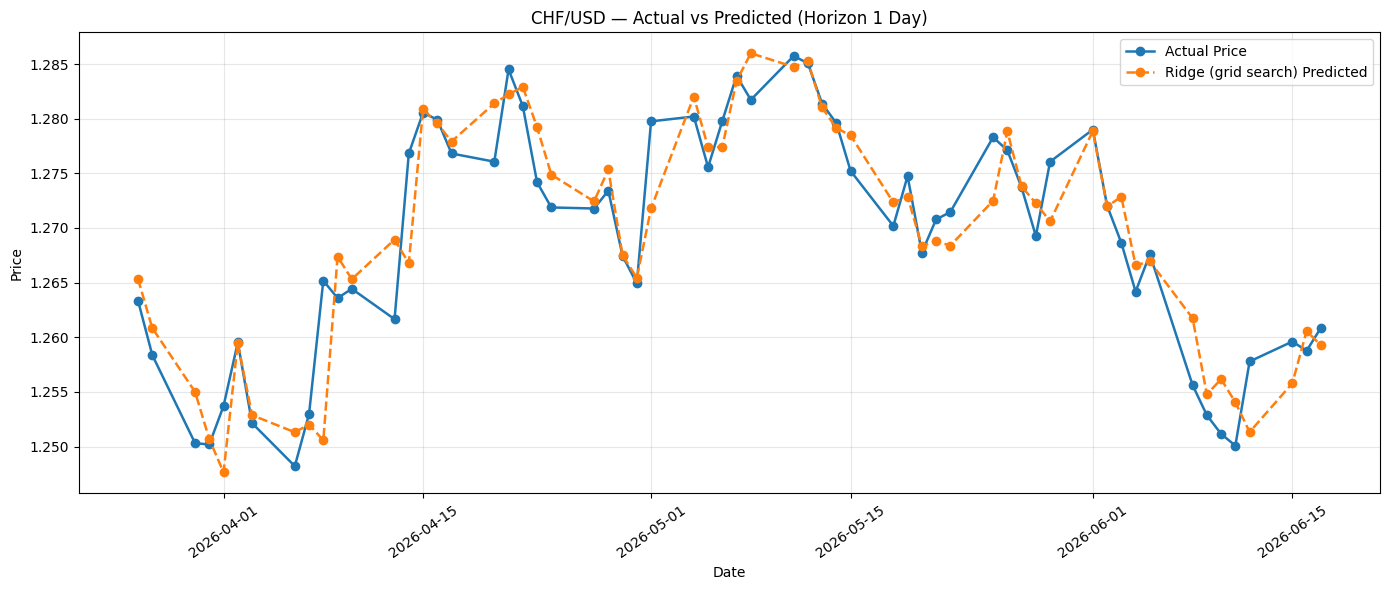

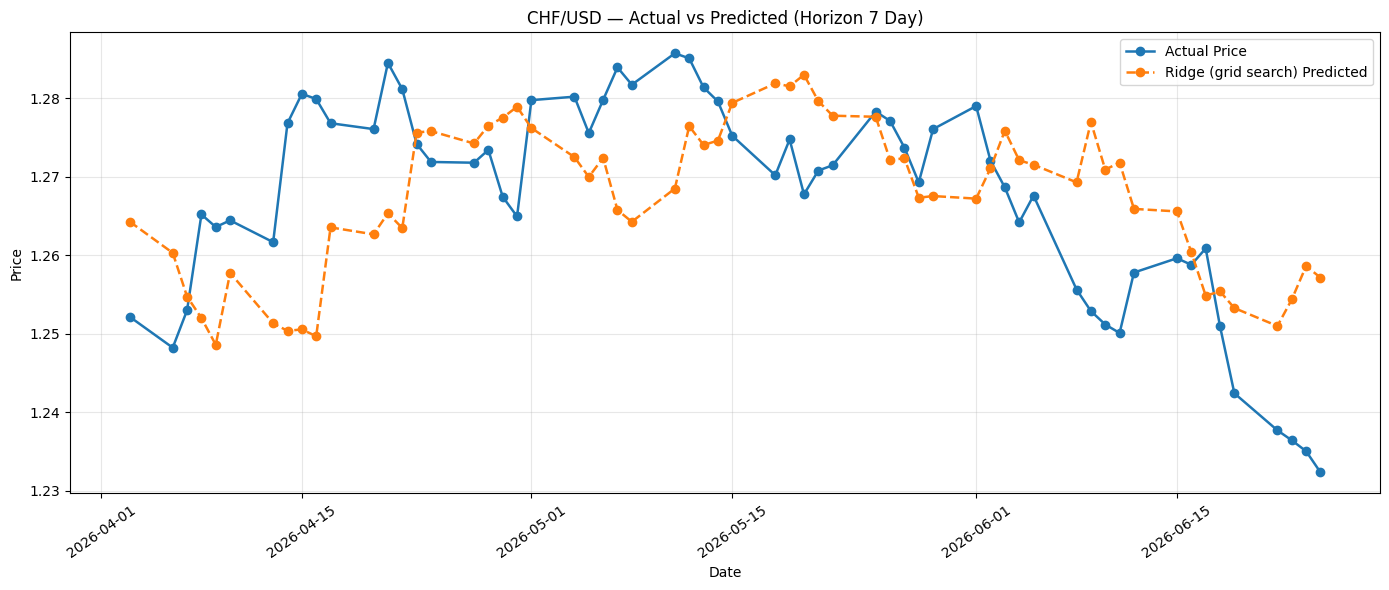

In [21]:
def plot_actual_vs_predicted(horizon=7, last_n=60):
    h_idx = HORIZONS.index(horizon)
    
    actual_h = y_test.to_numpy()[:, h_idx]
    pred_h = best_model.predict(X_test)[:, h_idx]

    plot_dates = pd.to_datetime(test_meta[f"target_date_{horizon}d"])

    plot_df = pd.DataFrame({
        "Date": plot_dates,
        "Actual": actual_h,
        "Predicted": pred_h
    }).dropna().tail(last_n)

    plt.figure(figsize=(14, 6))
    plt.plot(plot_df["Date"], plot_df["Actual"], marker="o", linewidth=1.8, label="Actual Price")
    plt.plot(plot_df["Date"], plot_df["Predicted"], marker="o", linestyle="--", linewidth=1.8, label=f"{best_model_name} Predicted")
    plt.title(f"{PAIR_NAME} — Actual vs Predicted (Horizon {horizon} Day)")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()

# Plot horizon 1 dan 7
plot_actual_vs_predicted(horizon=1, last_n=60)
plot_actual_vs_predicted(horizon=7, last_n=60)

In [22]:
final_model = clone(best_model)
final_model.fit(X, y)

model_bundle = {
    "model": final_model,
    "features": FEATURES,
    "horizons": HORIZONS,
    "target_type": "multi_horizon_price",
    "pair": PAIR,
    "pair_name": PAIR_NAME,
    "best_params": getattr(grid, 'best_params_', {}),
    "model_name": best_model_name
}

model_path = OUTPUT_DIR / "ridge_chfusd_multihorizon.pkl"
features_path = OUTPUT_DIR / "features_chfusd.json"

joblib.dump(model_bundle, model_path)
with open(features_path, "w") as f:
    json.dump(FEATURES, f)

print(f"Model saved: {model_path}")
print(f"Features saved: {features_path}")

Model saved: outputs_revisi\ridge_chfusd_multihorizon.pkl
Features saved: outputs_revisi\features_chfusd.json


In [23]:
latest_row = feature_df.dropna(subset=FEATURES).iloc[-1:].copy()
latest_X = latest_row[FEATURES]

latest_date = pd.to_datetime(latest_row["Date"].iloc[0])
latest_close = float(latest_row["Close"].iloc[0])

forecast_prices = final_model.predict(latest_X)[0]

future_dates = pd.bdate_range(latest_date + pd.offsets.BDay(1), periods=len(HORIZONS))

forecast_df = pd.DataFrame({
    "horizon": HORIZONS,
    "date": future_dates,
    "forecast_price": forecast_prices
})
forecast_df["last_close"] = latest_close
forecast_df["last_date"] = latest_date.strftime("%Y-%m-%d")
forecast_df["change_from_close"] = ((forecast_df["forecast_price"] / latest_close) - 1) * 100

forecast_df

,horizon,date,forecast_price,last_close,last_date,change_from_close
0,1,2026-06-26,1.231910,1.232316,2026-06-25,-0.032992
1,2,2026-06-29,1.232268,1.232316,2026-06-25,-0.003896
2,3,2026-06-30,1.232907,1.232316,2026-06-25,0.047913
3,4,2026-07-01,1.233139,1.232316,2026-06-25,0.066800
4,5,2026-07-02,1.233220,1.232316,2026-06-25,0.073323
5,6,2026-07-03,1.233302,1.232316,2026-06-25,0.080025
6,7,2026-07-06,1.233316,1.232316,2026-06-25,0.081114


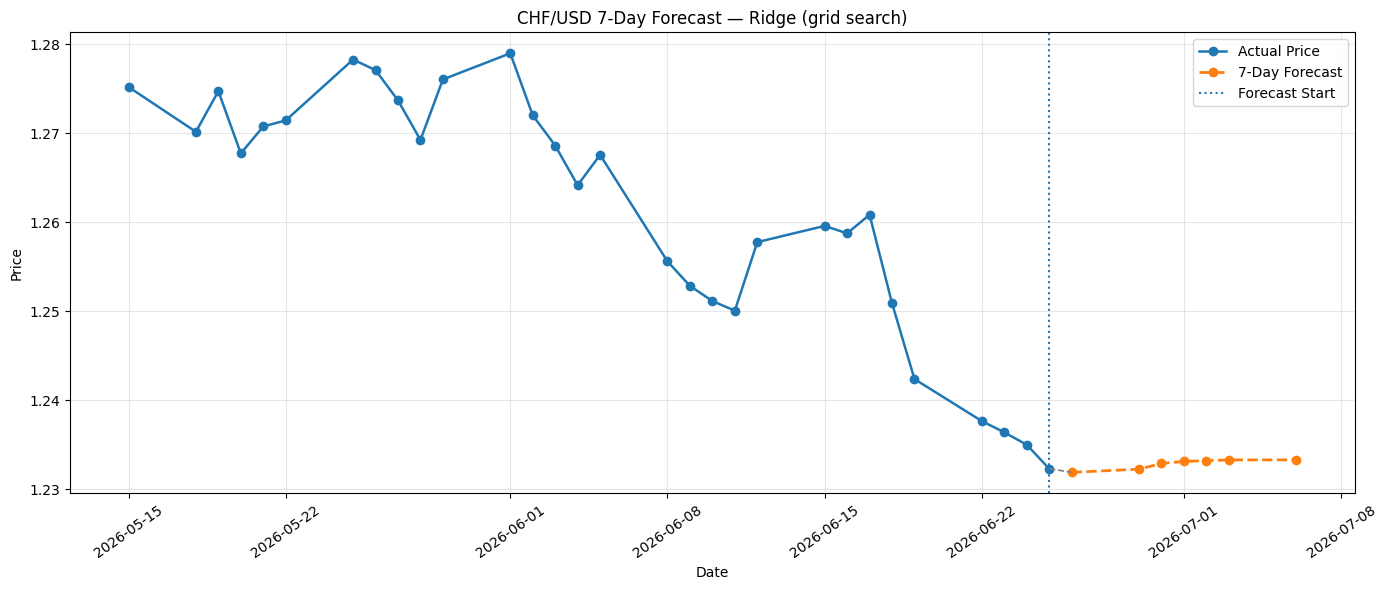

Last close: 1.23232
Forecast day 7: 1.23332
Expected change: +0.0811%


In [24]:
history_plot = feature_df.dropna(subset=["Close"]).tail(30)[["Date", "Close"]].copy()

plt.figure(figsize=(14, 6))
plt.plot(history_plot["Date"], history_plot["Close"], marker="o", linewidth=1.8, label="Actual Price")
plt.plot(forecast_df["date"], forecast_df["forecast_price"], marker="o", linestyle="--", linewidth=2.0, label="7-Day Forecast")

plt.plot(
    [history_plot["Date"].iloc[-1], forecast_df["date"].iloc[0]],
    [history_plot["Close"].iloc[-1], forecast_df["forecast_price"].iloc[0]],
    linestyle="--", linewidth=1.2, color="gray"
)

plt.axvline(history_plot["Date"].iloc[-1], linestyle=":", linewidth=1.5, label="Forecast Start")
plt.title(f"{PAIR_NAME} 7-Day Forecast — {best_model_name}")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

print(f"Last close: {latest_close:.5f}")
print(f"Forecast day 7: {forecast_df['forecast_price'].iloc[-1]:.5f}")
print(f"Expected change: {forecast_df['change_from_close'].iloc[-1]:+.4f}%")

In [25]:
eval_df.to_csv(OUTPUT_DIR / "metrics_chfusd.csv", index=False)
print(f"\nAll files saved to: {OUTPUT_DIR}/")


All files saved to: outputs_revisi/
